# Лабораторная работа №4: Байесовская сеть

## Цель

Научиться представлять зависимости между случайными величинами с помощью байесовской сети, самостоятельно строить структуру графа и выполнять вероятностный вывод при наличии дополнительной информации.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import pgmpy
import warnings
warnings.simplefilter("ignore")
%matplotlib inline

sns.set(style="darkgrid")

# Выбор данных

Для работы выбран открытый датасет **COVID-19 dataset** (Kaggle, автор Meir Nizri).
https://www.kaggle.com/datasets/meirnizri/covid19-dataset
**Один объект** — это один пациент, поступивший в больницу с подтверждённым диагнозом COVID-19.
Каждая строка таблицы описывает пол, возраст, наличие сопутствующих заболеваний у пациента, а также исход его госпитализации (выжил или умер).

## Переменные и их смысл

| Переменная | Тип | Описание |
|---|---|---|
| `SEX` | бинарная | пол пациента (1 — женский, 2 — мужской) |
| `AGE` | непрерывная | возраст пациента в годах |
| `CLASIFFICATION_FINAL` | категориальная | итог COVID-теста (1–3 — диагноз COVID разной степени, 4 и выше — не носитель/неинформативный тест) |
| `PATIENT_TYPE` | бинарная | тип помощи: 1 — отправлен домой, 2 — госпитализирован |
| `PNEUMONIA` | бинарная | есть ли воспаление лёгочных альвеол (пневмония) |
| `PREGNANT` | бинарная | беременна ли пациентка (1 — да, 2 — нет) |
| `DIABETES` | бинарная | есть ли сахарный диабет |
| `COPD` | бинарная | есть ли хроническая обструктивная болезнь лёгких |
| `ASTHMA` | бинарная | есть ли бронхиальная астма |
| `INMSUPR` | бинарная | есть ли иммуносупрессия (ослабленный иммунитет) |
| `HIPERTENSION` | бинарная | есть ли артериальная гипертензия |
| `CARDIOVASCULAR` | бинарная | есть ли заболевания сердца или сосудов |
| `RENAL_CHRONIC` | бинарная | есть ли хроническая болезнь почек |
| `OTHER_DISEASE` | бинарная | есть ли другие заболевания |
| `OBESITY` | бинарная | есть ли ожирение |
| `TOBACCO` | бинарная | употребляет ли пациент табак |
| `USMER` | бинарная | обращался ли пациент в мед. учреждения первого/второго/третьего уровня |
| `MEDICAL_UNIT` | категориальная | тип учреждения национальной системы здравоохранения, оказавшего помощь |
| `INTUBED` | бинарная | подключался ли пациент к аппарату ИВЛ |
| `ICU` | бинарная | поступал ли пациент в отделение реанимации |
| `DATE_DIED` | дата/бинарная | дата смерти или признак того, что пациент выжил |

В булевых признаках `1` означает «да», `2` — «нет», а значения `97` и `99` — пропущенные данные.
Между признаками можно содержательно предположить причинно-следственные связи:

- **возраст предшествует болезням**: с возрастом растёт вероятность хронических заболеваний (диабет, гипертензия, болезни сердца и почек, ХОБЛ);
- **сопутствующие заболевания повышают риск осложнений**: например, диабет и болезни лёгких увеличивают вероятность пневмонии;
- **осложнения ведут к тяжёлому течению**: пневмония повышает шанс попадания в реанимацию, а в реанимации может потребоваться интубация;
- **возраст, тяжёлые заболевания и осложнения влияют на исход**: всё перечисленное увеличивает вероятность летального исхода.

# Подготовка данных
В исходном датасете 21 признак. Сначала исследуем пропущенные значения по всем столбцам, затем решим, какие признаки оставить в сети.

In [28]:
initData = pd.read_csv('Covid Data.csv')
for col in initData.columns:
    print(initData[col].value_counts())

USMER
2    662903
1    385672
Name: count, dtype: int64
MEDICAL_UNIT
12    602995
4     314405
6      40584
9      38116
3      19175
8      10399
10      7873
5       7244
11      5577
13       996
7        891
2        169
1        151
Name: count, dtype: int64
SEX
1    525064
2    523511
Name: count, dtype: int64
PATIENT_TYPE
1    848544
2    200031
Name: count, dtype: int64
DATE_DIED
9999-99-99    971633
06/07/2020      1000
07/07/2020       996
13/07/2020       990
16/06/2020       979
               ...  
27/03/2021         1
31/03/2021         1
02/04/2021         1
13/04/2021         1
22/04/2021         1
Name: count, Length: 401, dtype: int64
INTUBED
97    848544
2     159050
1      33656
99      7325
Name: count, dtype: int64
PNEUMONIA
2     892534
1     140038
99     16003
Name: count, dtype: int64
AGE
30     27010
31     25927
28     25313
29     25134
34     24872
       ...  
118        2
115        2
111        1
121        1
113        1
Name: count, Length: 121, dtype

"DATE_DIED" можно преобразовать в факт того живой ли человек. "AGE" нужно дискретизировать, дискретизация будет на основе стандартов ВОЗ и гистограмме. Остальные признаки бинарные, но у некоторых есть пропущенные значения.

<Axes: >

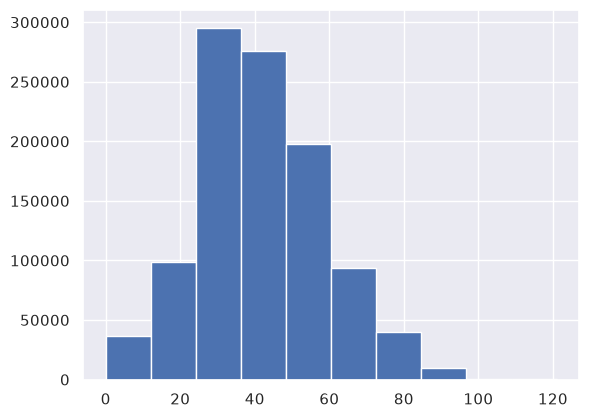

In [ ]:
data["AGE"].hist()

У нас достаточно данных, чтобы поделить пациентов на следующие возрастные группы.
- 0–17
- 18–29
- 30–39
- 40–49
- 50–59
- 60–69
- 70–79
- 80+

Теперь осталось понять, что делать с пропущенными значениями. Посмотрим как много у нас пропущенных.

In [ ]:
# Boolean-признаки: 1 = «да», 2 = «нет», а 97/98/99 = пропущенные данные.
BINARY_COLS = [
    'PNEUMONIA', 'PREGNANT', 'DIABETES', 'COPD', 'ASTHMA', 'INMSUPR',
    'HIPERTENSION', 'CARDIOVASCULAR', 'RENAL_CHRONIC', 'OTHER_DISEASE',
    'OBESITY', 'TOBACCO', 'USMER', 'INTUBED', 'ICU',
]

# Считаем пропуски по всем столбцам исходных данных
raw = initData.copy()
missing_counts = {}
for col in raw.columns:
    # настоящие NaN
    is_nan = raw[col].isna()
    # коды-заглушки 97/98/99 (актуально для boolean-признаков)
    is_sentinel = raw[col].isin([97, 98, 99]) if col in BINARY_COLS else pd.Series(False, index=raw.index)
    missing_counts[col] = int((is_nan | is_sentinel).sum())

missing_df = (
    pd.Series(missing_counts, name='пропусков')
    .sort_values(ascending=False)
    .to_frame()
)

missing_df['доля, %'] = (missing_df['пропусков'] / len(raw) * 100).round(2)
print('Пропущенные значения по столбцам (NaN + коды 97/98/99):')
print(missing_df)
print(f'\nВсего строк: {len(raw)}')

Пропущенные значения по столбцам (NaN + коды 97/98/99):
                      пропусков  доля, %
ICU                      856032    81.64
INTUBED                  855869    81.62
PREGNANT                 527265    50.28
PNEUMONIA                 16003     1.53
OTHER_DISEASE              5045     0.48
INMSUPR                    3404     0.32
DIABETES                   3338     0.32
TOBACCO                    3220     0.31
HIPERTENSION               3104     0.30
CARDIOVASCULAR             3076     0.29
OBESITY                    3032     0.29
RENAL_CHRONIC              3006     0.29
COPD                       3003     0.29
ASTHMA                     2979     0.28
DATE_DIED                     0     0.00
SEX                           0     0.00
MEDICAL_UNIT                  0     0.00
USMER                         0     0.00
PATIENT_TYPE                  0     0.00
AGE                           0     0.00
CLASIFFICATION_FINAL          0     0.00

Всего строк: 1048575


## Какие признаки оставляем
Оставляем признаки с наименьшим количеством пропусков. Будем исследовать 8 переменных, 7 - признаки, которые предположительно сильнее всего влияют на вероятность летального исхода от ковида и 1 - факт летального исхода.

In [79]:
import pandas as pd
ALIVE_DATE = '9999-99-99'
USED_COLUMNS = ("SEX", "AGE", "DIABETES", "HIPERTENSION", "CARDIOVASCULAR", "COPD", "PNEUMONIA", "DATE_DIED")
BINARY_COLUMNS = ("SEX", "DIABETES", "HIPERTENSION", "CARDIOVASCULAR", "COPD", "PNEUMONIA")
AGE_BINS = [0, 18, 30, 40, 50, 60, 70, 80, float('inf')]
def prepareCovid(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df = df[list(USED_COLUMNS)]
    #transforming date of death to fact of lethal outcome 
    df['DEATH'] = (df['DATE_DIED'] != ALIVE_DATE).astype(int)
    df = df.drop(columns=['DATE_DIED'])
    #transform to binary
    for c in BINARY_COLUMNS:
        df[c] = df[c].replace({1:1, 2:0})
        df[c] = df[c].where(df[c].isin([0, 1]))
    #discretization of age
    df["AGE"] = pd.cut(df["AGE"], labels=range(len(AGE_BINS)-1), bins=AGE_BINS, right=False, include_lowest=True)
    df = df.dropna()
    df["AGE"] = df["AGE"].astype(int)
    return df
preparedData = prepareCovid(initData) 
preparedData.head()
print(preparedData.shape)

(1028345, 8)


## Редкие категории
Посмотрим на доли каждого значения каждого признака в датасете.

In [78]:
# Доли каждого значения в каждой переменной
rows = []
for col in preparedData.columns:
    vc = preparedData[col].value_counts(normalize=True).sort_index()
    for val, share in vc.items():
        rows.append({
            "признак": col,
            "значение": val,
            "количество": int(preparedData[col].value_counts().loc[val]),
            "доля, %": round(share * 100, 2),
        })

shareTable = pd.DataFrame(rows)[["признак", "значение", "количество", "доля, %"]]
shareTable


,признак,значение,количество,"доля, %"
0,SEX,0.0,513698,49.95
1,SEX,1.0,514647,50.05
2,AGE,0.0,49583,4.82
3,AGE,1.0,196367,19.10
4,AGE,2.0,246121,23.93
5,AGE,3.0,220408,21.43
6,AGE,4.0,162247,15.78
7,AGE,5.0,87948,8.55
8,AGE,6.0,44188,4.30
9,AGE,7.0,21483,2.09


Мы можем увидеть, что у нас мало пациентов с сердечно-сосудистыми заболеваниями, пациентов с COPD, пациентов младше 18 и старше 60. В целом есть представители каждой категории.

# Постановка вопросов
1. Как изменится вероятность летального исхода, если у пациента обнаружат пневмонию?
2. Какова вероятность летального исхода, если пациент мужчина 50 лет с сердечно-сосудистым заболеванием?
3. Как изменится вероятность летального исхода, если у пациента ХОБЛ, но нет пневмонии?

Узлы сети: ['AGE', 'CARDIOVASCULAR', 'COPD', 'DEATH', 'DIABETES', 'HIPERTENSION', 'PNEUMONIA', 'SEX']
Рёбра сети: [('AGE', 'CARDIOVASCULAR'), ('AGE', 'COPD'), ('AGE', 'DEATH'), ('AGE', 'DIABETES'), ('AGE', 'HIPERTENSION'), ('CARDIOVASCULAR', 'DEATH'), ('COPD', 'PNEUMONIA'), ('DIABETES', 'PNEUMONIA'), ('HIPERTENSION', 'CARDIOVASCULAR'), ('PNEUMONIA', 'DEATH'), ('SEX', 'CARDIOVASCULAR'), ('SEX', 'DIABETES'), ('SEX', 'HIPERTENSION')]


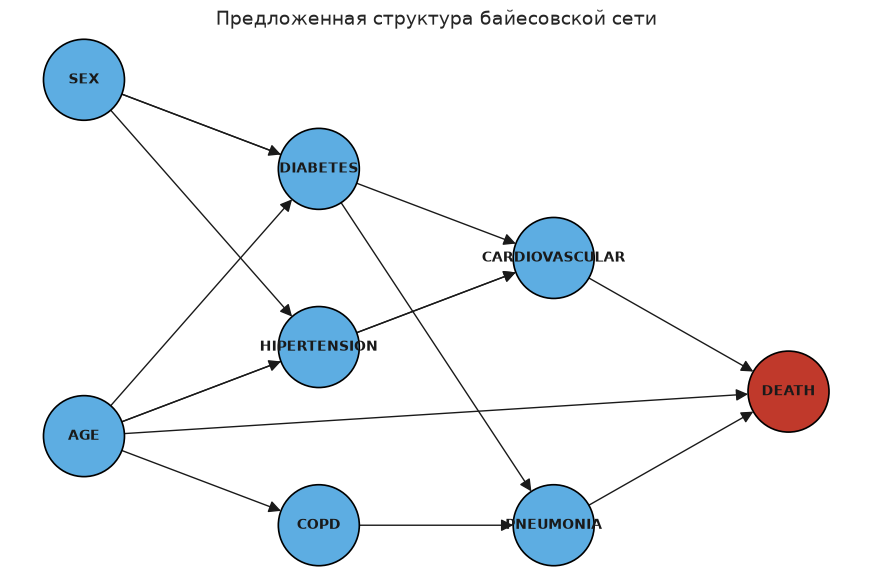

In [75]:
# Построение структуры байесовской сети (DAG)
import networkx as nx
from pgmpy.models import DiscreteBayesianNetwork

# Рёбра графа: (родитель, ребёнок)
EDGES = [
    ("AGE", "DIABETES"),
    ("AGE", "HIPERTENSION"),
    ("AGE", "CARDIOVASCULAR"),
    ("AGE", "COPD"),
    ("HIPERTENSION", "CARDIOVASCULAR"),
    ("SEX", "DIABETES"),
    ("SEX", "HIPERTENSION"),
    ("SEX", "CARDIOVASCULAR"),
    ("DIABETES", "PNEUMONIA"),
    ("COPD", "PNEUMONIA"),
    ("AGE", "DEATH"),
    ("PNEUMONIA", "DEATH"),
    ("CARDIOVASCULAR", "DEATH"),
]

model = DiscreteBayesianNetwork(EDGES)
print("Узлы сети:", sorted(model.nodes()))
print("Рёбра сети:", sorted(model.edges()))
assert nx.is_directed_acyclic_graph(model), "Граф не является DAG!"

# Ручная послойная компоновка для читаемости
LAYER = {
    "SEX": (0.0, 1.0),
    "AGE": (0.0, 0.6),
    "DIABETES": (1.0, 0.9),
    "HIPERTENSION": (1.0, 0.7),
    "COPD": (1.0, 0.5),
    "CARDIOVASCULAR": (2.0, 0.8),
    "PNEUMONIA": (2.0, 0.5),
    "DEATH": (3.0, 0.65),
}

plt.figure(figsize=(11, 7))
node_colors = ["#C0392B" if n == "DEATH" else "#5DADE2" for n in model.nodes()]
nx.draw_networkx(
    model,
    pos=LAYER,
    node_color=node_colors,
    node_size=3400,
    edgecolors="black",
    linewidths=1.2,
    font_size=10,
    font_weight="bold",
    arrows=True,
    arrowsize=18,
    arrowstyle="-|>",
)
plt.title("Предложенная структура байесовской сети", fontsize=14)
plt.axis("off")
plt.show()


## Обоснование структуры графа

Рёбра выбраны из **причинно-следственных** соображений (медицинская логика и временной порядок). Ниже объяснены направления основных связей.

### Демография → болезни

- **AGE → DIABETES, HIPERTENSION, CARDIOVASCULAR, COPD** — возраст хронологически предшествует хроническим заболеваниям и является их общей причиной: с возрастом растёт вероятность диабета, гипертензии, болезней сердца и сосудов, ХОБЛ. 
- **SEX → DIABETES, HIPERTENSION, CARDIOVASCULAR** — пол задан при рождении и тоже предшествует болезням; распространённость ряда заболеваний различается между мужчинами и женщинами, поэтому пол рассматривается как фактор, влияющий на вероятность болезней.

### Связи между болезнями

- **HIPERTENSION → CARDIOVASCULAR** — гипертония является установленным фактором риска сердечно-сосудистых заболеваний. Направление задаётся медицинским знанием: гипертония предшествует и способствует болезням сердца/сосудов.

### Болезни → осложнение

- **DIABETES → PNEUMONIA** — диабет ослабляет иммунитет и повышает восприимчивость к инфекциям, в том числе к пневмонии.
- **COPD → PNEUMONIA** — ХОБЛ повреждает лёгкие, из-за чего повышается риск воспаления лёгочной ткани.

Здесь направление тоже причинное: болезнь предшествует осложнению и делает его более вероятным.

### Причины летального исхода

- **AGE → DEATH** — возраст напрямую влияет на исход: пожилой возраст сам по себе является фактором риска смерти, независимо от перечисленных болезней.
- **PNEUMONIA → DEATH** — пневмония (поражение лёгких) напрямую ухудшает прогноз и повышает вероятность летального исхода.
- **CARDIOVASCULAR → DEATH** — тяжёлые сердечно-сосудистые заболевания напрямую повышают риск смерти.

In [76]:
from pgmpy.parameter_estimator import DiscreteMLE
model.fit(preparedData, estimator=DiscreteMLE())

# Условные вероятности

Оценим параметры сети методом максимального правдоподобия: каждая условная вероятность — это частота значения в данных при условии значений родителей.


In [77]:
from itertools import product
from IPython.display import display

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)

def cpd_table(cpd):
    node = cpd.variable
    parents = cpd.variables[1:]
    values = cpd.get_values()                    # (состояния узла, комбинации родителей)
    node_states = cpd.state_names[node]
    df = pd.DataFrame(values.T, columns=[f"{node}={s}" for s in node_states])
    if parents:
        combos = list(product(*[cpd.state_names[p] for p in parents]))
        df.insert(0, "условия", [", ".join(f"{p}={s}" for p, s in zip(parents, combo)) for combo in combos])
    else:
        df.insert(0, "условия", ["безусловно"])
    return df

INTEREST_COLUMNS = ("DEATH", "PNEUMONIA", "CARDIOVASCULAR")
for col in INTEREST_COLUMNS:
    print(f"===== CPD: {col} =====")
    display(cpd_table(model.get_cpds(col)).round(3))
    print()


===== CPD: DEATH =====


,условия,DEATH=0,DEATH=1
0,"AGE=0, CARDIOVASCULAR=0.0, PNEUMONIA=0.0",0.994,0.006
1,"AGE=0, CARDIOVASCULAR=0.0, PNEUMONIA=1.0",0.908,0.092
2,"AGE=0, CARDIOVASCULAR=1.0, PNEUMONIA=0.0",0.941,0.059
3,"AGE=0, CARDIOVASCULAR=1.0, PNEUMONIA=1.0",0.838,0.162
4,"AGE=1, CARDIOVASCULAR=0.0, PNEUMONIA=0.0",0.998,0.002
5,"AGE=1, CARDIOVASCULAR=0.0, PNEUMONIA=1.0",0.888,0.112
6,"AGE=1, CARDIOVASCULAR=1.0, PNEUMONIA=0.0",0.985,0.015
7,"AGE=1, CARDIOVASCULAR=1.0, PNEUMONIA=1.0",0.780,0.220
8,"AGE=2, CARDIOVASCULAR=0.0, PNEUMONIA=0.0",0.995,0.005
9,"AGE=2, CARDIOVASCULAR=0.0, PNEUMONIA=1.0",0.835,0.165



===== CPD: PNEUMONIA =====


,условия,PNEUMONIA=0.0,PNEUMONIA=1.0
0,"COPD=0.0, DIABETES=0.0",0.895,0.105
1,"COPD=0.0, DIABETES=1.0",0.670,0.330
2,"COPD=1.0, DIABETES=0.0",0.636,0.364
3,"COPD=1.0, DIABETES=1.0",0.536,0.464



===== CPD: CARDIOVASCULAR =====


,условия,CARDIOVASCULAR=0.0,CARDIOVASCULAR=1.0
0,"AGE=0, HIPERTENSION=0.0, SEX=0",0.987,0.013
1,"AGE=0, HIPERTENSION=0.0, SEX=1",0.987,0.013
2,"AGE=0, HIPERTENSION=1.0, SEX=0",0.916,0.084
3,"AGE=0, HIPERTENSION=1.0, SEX=1",0.866,0.134
4,"AGE=1, HIPERTENSION=0.0, SEX=0",0.996,0.004
5,"AGE=1, HIPERTENSION=0.0, SEX=1",0.995,0.005
6,"AGE=1, HIPERTENSION=1.0, SEX=0",0.952,0.048
7,"AGE=1, HIPERTENSION=1.0, SEX=1",0.946,0.054
8,"AGE=2, HIPERTENSION=0.0, SEX=0",0.994,0.006
9,"AGE=2, HIPERTENSION=0.0, SEX=1",0.994,0.006


Условные вероятности согласуются с моими ожиданиями.

# Вероятностный вывод
Ответим на вопросы из начала работы.

# Вероятностный вывод

Ответим на три вопроса, сформулированные в начале работы, и сравним априорную и апостериорную вероятности летального исхода. Вывод выполняем алгоритмом `VariableElimination`.

Кодировка состояний после подготовки данных:
- `DEATH`: 1 — умер, 0 — выжил;
- `SEX`: 0 — мужчина, 1 — женщина;
- болезни: 1 — есть, 0 — нет;
- `AGE`: целое число — номер возрастной группы (50 лет попадает в группу `[50, 60)`, то есть `AGE=4`).


In [81]:
from pgmpy.inference import VariableElimination

infer = VariableElimination(model)

def p_death(evidence=None):
    """Вероятность летального исхода P(DEATH=1) при заданном evidence."""
    result = infer.query(
        variables=["DEATH"],
        evidence={} if evidence is None else dict(evidence),
        show_progress=False,
    )
    return float(result.get_value(DEATH=1))

# Априорная вероятность летального исхода (без наблюдений)
prior = p_death()

# Три вопроса и соответствующие evidence
queries = [
    ("1. Обнаружена пневмония", {"PNEUMONIA": 1}),
    ("2. Мужчина 50 лет с ССЗ", {"SEX": 0, "AGE": 4, "CARDIOVASCULAR": 1}),
    ("3. ХОБЛ, но нет пневмонии", {"PNEUMONIA": 0, "COPD": 1}),
]

rows = []
for name, evidence in queries:
    post = p_death(evidence)
    rows.append({
        "Вопрос": name,
        "Evidence": ", ".join(f"{k}={v}" for k, v in evidence.items()),
        "P(DEATH=1), %": prior * 100,
        "P(DEATH=1 | evidence), %": post * 100,
        "Δ, п.п.": (post - prior) * 100,
    })

comparison = pd.DataFrame(rows)
comparison[["P(DEATH=1), %", "P(DEATH=1 | evidence), %", "Δ, п.п."]] = \
    comparison[["P(DEATH=1), %", "P(DEATH=1 | evidence), %", "Δ, п.п."]].round(1)
comparison


,Вопрос,Evidence,"P(DEATH=1), %","P(DEATH=1 | evidence), %","Δ, п.п."
0,1. Обнаружена пневмония,PNEUMONIA=1,6.6,30.2,23.6
1,2. Мужчина 50 лет с ССЗ,"SEX=0, AGE=4, CARDIOVASCULAR=1",6.6,12.0,5.4
2,"3. ХОБЛ, но нет пневмонии","PNEUMONIA=0, COPD=1",6.6,10.9,4.4


Можем увидеть, что люди с пневмонией более вероятно погибнут от ковида, чем обычные люди. У мужчина 50 лет с сердечно-сосудистыми заболеваниями повышается вероятность гибели от ковида. Этот вопрос задается скорее просто для определения вероятности гибели конкретных пациентов.
Если у пациента есть ХОБЛ, но нет пневмонии, то вероятность летального исхода будет ниже, чем если бы было известно, что у пациента была пневмония. Это значит, что симптом пневмонии губительнее для пациента, чем просто заболевание ХОБЛ.

# Эксперимент с evidence

Выберем целевую переменную — летальный исход `DEATH` — и будем последовательно добавлять информацию о других переменных, наблюдая за изменением распределения `P(DEATH)`.

Порядок наблюдений соответствует причинной цепочке сети: сначала известен возраст, затем добавляем сердечно-сосудистое заболевание, затем пневмонию и, наконец, ХОБЛ.


,Наблюдения,"P(DEATH=0), %","P(DEATH=1), %"
0,Ничего не известно,93.4,6.6
1,AGE=7 (80+),71.7,28.3
2,+ CARDIOVASCULAR=1,71.6,28.4
3,+ PNEUMONIA=1,47.1,52.9
4,+ COPD=1,47.1,52.9


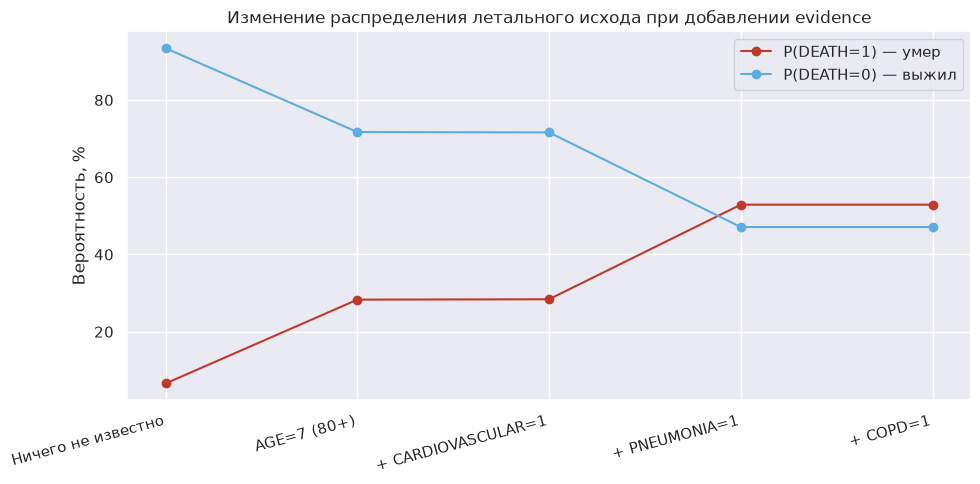

In [ ]:
from pgmpy.inference import VariableElimination
from IPython.display import display

infer = VariableElimination(model)

def death_distribution(evidence=None):
    """Распределение P(DEATH | evidence)."""
    return infer.query(
        variables=["DEATH"],
        evidence={} if evidence is None else dict(evidence),
        show_progress=False,
    )

steps = [
    ("Ничего не известно", None),
    ("AGE=7 (80+)", {"AGE": 7}),
    ("+ CARDIOVASCULAR=1", {"AGE": 7, "CARDIOVASCULAR": 1}),
    ("+ PNEUMONIA=1", {"AGE": 7, "CARDIOVASCULAR": 1, "PNEUMONIA": 1}),
    ("+ COPD=1", {"AGE": 7, "CARDIOVASCULAR": 1, "PNEUMONIA": 1, "COPD": 1}),
]

rows = []
for name, evidence in steps:
    dist = death_distribution(evidence)
    rows.append({
        "Наблюдения": name,
        "P(DEATH=0), %": float(dist.get_value(DEATH=0)) * 100,
        "P(DEATH=1), %": float(dist.get_value(DEATH=1)) * 100,
    })

evidence_table = pd.DataFrame(rows)
evidence_table[["P(DEATH=0), %", "P(DEATH=1), %"]] = \
    evidence_table[["P(DEATH=0), %", "P(DEATH=1), %"]].round(1)
display(evidence_table)

fig, ax = plt.subplots(figsize=(10, 5))
x = range(len(evidence_table))
ax.plot(x, evidence_table["P(DEATH=1), %"], marker="o", color="#C0392B", label="P(DEATH=1) — умер")
ax.plot(x, evidence_table["P(DEATH=0), %"], marker="o", color="#5DADE2", label="P(DEATH=0) — выжил")
ax.set_xticks(list(x))
ax.set_xticklabels(evidence_table["Наблюдения"], rotation=15, ha="right")
ax.set_ylabel("Вероятность, %")
ax.set_title("Изменение распределения летального исхода при добавлении evidence")
ax.legend()
fig.tight_layout()
plt.show()


Добавление того факта, что возраст пациента больше 80 сильно повышает вероятность летального исхода. После этого добавление факта о сердечно-сосудистом заболевании почти не изменяет вероятность. Возможно это связано с тем, что у пациентов старше 80 частно наблюдаются эти заболевания. Проверим.

In [ ]:
elder = preparedData[preparedData['AGE'] == 7]
print(f"Доля пожилых с ССЗ: {len(elder[elder['CARDIOVASCULAR'] == 1])/len(elder)}")
elderDead = elder[elder['DEATH'] == 1]
print(f"Доля погибших пожилых: {len(elderDead) / len(elder)}")
print(f"Доля погибших пожилых с ССЗ: {len(elderDead[elderDead['CARDIOVASCULAR'] == 1]) / len(elder)}")

Доля пожилых с ССЗ: 0.11474188893543733
Доля погибших пожилых: 0.3727598566308244


## Интерпретация

По структуре сети `CARDIOVASCULAR` — прямой родитель `DEATH`, поэтому ожидается, что факт ССЗ повышает вероятность летального исхода. Если на графике этого не видно, причина — в данных, а не в структуре графа.

Два объяснения:

1. **Возраст — сильный общий родитель.** `AGE` влияет и на `CARDIOVASCULAR`, и на `DEATH`. В старшей группе (80+) смертность и без того высока: возраст уже объясняет большую часть риска, поэтому добавление ССЗ почти не меняет вероятность.

2. **Разреженность данных.** ССЗ встречается редко (~2% выборки). В пересечении «80+ и ССЗ» наблюдений мало, и оценка MLE в этой ячейке получается шумной.

Важно: MLE оценивает частоты по данным, а не воспроизводит нашу причинную гипотезу. Направление стрелки `CARDIOVASCULAR → DEATH` — это предположение, а наблюдаемая условная зависимость в данных может оказаться слабой.

Подтвердим механизм, а не сам ответ: покажем, что возраст — общий родитель (одновременно связан и с ССЗ, и со смертностью), и что ячейка «80+ и ССЗ» разрежена.


In [ ]:
from IPython.display import display

# Механизм 1: возраст — общий родитель.
# С возрастом растёт И распространённость ССЗ, И смертность.
by_age = preparedData.groupby("AGE").agg(
    n=("DEATH", "count"),
    p_cvd=("CARDIOVASCULAR", "mean"),
    p_death=("DEATH", "mean"),
)
by_age["P(ССЗ=1), %"] = (by_age["p_cvd"] * 100).round(2)
by_age["P(DEATH=1), %"] = (by_age["p_death"] * 100).round(2)
by_age = by_age[["n", "P(ССЗ=1), %", "P(DEATH=1), %"]].rename(columns={"n": "наблюдений"})
print("Возраст связан и с ССЗ, и со смертностью (общий родитель):")
display(by_age)

# Механизм 2: разреженность данных — сколько наблюдений в ячейках AGE × CARDIOVASCULAR
counts = pd.crosstab(preparedData["AGE"], preparedData["CARDIOVASCULAR"])
counts.columns = ["без ССЗ", "с ССЗ"]
counts.index.name = "AGE"
print("Число наблюдений AGE × CARDIOVASCULAR:")
display(counts)


Возраст связан и с ССЗ, и со смертностью (общий родитель):


,наблюдений,"P(ССЗ=1), %","P(DEATH=1), %"
AGE,,,
0,49583,1.33,1.47
1,196367,0.56,0.68
2,246121,0.74,1.55
3,220408,1.26,4.30
4,162247,2.32,10.52
5,87948,4.70,22.77
6,44188,8.08,33.54
7,21483,11.47,37.28


Число наблюдений AGE × CARDIOVASCULAR:


,без ССЗ,с ССЗ
AGE,,
0,48924,659
1,195268,1099
2,244307,1814
3,217636,2772
4,158479,3768
5,83812,4136
6,40616,3572
7,19018,2465


Далее пневмония увеличивает риск летального исхода, что логично из предметной области. Наличие ХОБЛ не добавляет вероятности, потому что в сети летальный исход зависит от ХОБЛ только через пневмонию, а факт пневмонии уже известен.

# Анализ структуры

Удалим ребро `AGE → DEATH` и посмотрим, как изменится вероятностный вывод. В исходной сети возраст влияет на летальный исход и напрямую, и косвенно (через болезни). После удаления ребра останется только косвенный путь `AGE → болезни → DEATH`.

Обучим изменённую сеть заново (MLE) и повторим те же запросы.


In [93]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.parameter_estimator import DiscreteMLE
from pgmpy.inference import VariableElimination

# Удаляем ребро AGE -> DEATH
reduced_edges = [e for e in model.edges() if e != ("AGE", "DEATH")]
print("Удалено ребро:", ("AGE", "DEATH"))

reduced_model = DiscreteBayesianNetwork(reduced_edges)
reduced_model.fit(preparedData, estimator=DiscreteMLE())
print("Изменённая модель корректна:", reduced_model.check_model())

infer_orig = VariableElimination(model)
infer_red = VariableElimination(reduced_model)

def p_death(infer, evidence=None):
    result = infer.query(
        variables=["DEATH"],
        evidence={} if evidence is None else dict(evidence),
        show_progress=False,
    )
    return float(result.get_value(DEATH=1))

queries = [
    ("Мужчина 50 лет с ССЗ", {"SEX": 0, "AGE": 4, "CARDIOVASCULAR": 1}),
]

rows = []
for name, ev in queries:
    orig = p_death(infer_orig, ev)
    red = p_death(infer_red, ev)
    rows.append({
        "Запрос": name,
        "Исходная, %": orig * 100,
        "Без AGE→DEATH, %": red * 100,
        "Δ, п.п.": (red - orig) * 100,
    })

comparison = pd.DataFrame(rows)
comparison[["Исходная, %", "Без AGE→DEATH, %", "Δ, п.п."]] = \
    comparison[["Исходная, %", "Без AGE→DEATH, %", "Δ, п.п."]].round(1)
comparison


Удалено ребро: ('AGE', 'DEATH')
Изменённая модель корректна: True


,Запрос,"Исходная, %","Без AGE→DEATH, %","Δ, п.п."
0,Мужчина 50 лет с ССЗ,12.0,15.1,3.1


Видим, что вероятность увеличилась на 3%. 

## Объяснение

Результат изменился: после удаления ребра `AGE → DEATH` вероятность летального исхода для того же пациента (мужчина 50 лет с ССЗ) выросла примерно на 3 п.п. Это показывает, что структура графа напрямую влияет на вероятностный вывод.

Почему так происходит. Удаление ребра меняет факторизацию совместного распределения. В исходной сети летальный исход зависел от возраста напрямую через CPD `P(DEATH | AGE, PNEUMONIA, CARDIOVASCULAR)`. После удаления ребра CPD переоценивается как `P(DEATH | PNEUMONIA, CARDIOVASCULAR)`, и влияние возраста на смерть передаётся только косвенным путём `AGE → болезни → DEATH`. MLE заново распределяет вероятности под новую структуру, поэтому один и тот же запрос даёт другой ответ.

Насколько уверенно можно выбирать направление рёбер только по данным. По одним наблюдаемым данным выбрать направление нельзя. Наблюдения дают лишь условные независимости, а множество разных DAG (в том числе марковски эквивалентных) одинаково хорошо описывают одни и те же данные. Направление `AGE → DEATH` мы выбрали из временного порядка и медицинского смысла, а не из данных. Опираясь только на данные, мы не смогли бы отличить это ребро от альтернативных структур с той же факторизацией.


# Причинность

Строго говоря, построенную сеть нельзя считать причинной моделью. 

При этом часть рёбер мы обосновали причинно, а не корреляционно:
- **временной порядок** — возраст предшествует болезням, поэтому стрелки `AGE → болезни` причинно правдоподобны;
- **медицинское знание** — гипертония является фактором риска сердечно-сосудистых заболеваний, поэтому `HIPERTENSION → CARDIOVASCULAR`.

Однако это всё ещё предположения. Хорошая иллюстрация — ребро `CARDIOVASCULAR → DEATH`: мы провели его по гипотезе, что ССЗ повышает риск смерти, но в данных при фиксированном возрасте ССЗ почти не меняло вероятность летального исхода. То есть стрелка отражает нашу гипотезу, а не измеренный причинный эффект.

Для настоящего причинного вывода нужны либо дополнительные допущения, либо интервенционные данные (`do`-оператор), которых в этом датасете нет. Поэтому корректно называть нашу модель вероятностной сетью с причинно обоснованной, но не доказанной структурой.


# Итог

- **Что удалось узнать.** Сеть позволяет оценивать вероятность летального исхода и отслеживать, как она меняется при появлении информации о пациенте (пневмония, возраст, ССЗ).
- **Наиболее интересные зависимости.** Пневмония заметно повышает смертность; возраст — общий родитель болезней и смерти; ССЗ после учёта возраста влияет слабо (конфаундинг возрастом и разреженность данных).
- **Влияние evidence.** Последовательное добавление признаков меняет распределение `DEATH`: возраст и пневмония дают наибольший сдвиг, а ХОБЛ при уже известной пневмонии — почти ничего.
- **Зависимость от структуры.** Результаты зависят от выбранного графа: удаление ребра `AGE → DEATH` изменило ответ примерно на 3 п.п.
- **Ограничения.** Грубая дискретизация возраста; редкие категории (ССЗ, ХОБЛ) дают шумные оценки CPD; MLE без сглаживания; граф — гипотеза, а направление рёбер не выводится из данных; возможное смещение выборки.
